# DSCI-503: Project 02

**Mame Diarra N'daw**

[PLACEHOLDER_FOR_NOTEBOOK_LINK]

## Getting Started

Follow the instructions below to copy this notebook and to perform some initial setup.

1. Copy this notebook by selecting `File > Save a copy in Drive`.
2. A new window should open for the copied notebook. Move the new notebook to your course folder in Google Drive by selecting `File > Move` and then selecting the desired folder.
3. Update the name of the notebook by removing "Copy of" and replacing "Username" with your actual username.
4. Update the first cell in the notebook by replacing "Student Name" with your actual name.
5. Do not edit the line that says `PLACEHOLDER_FOR_NOTEBOOK_LINK`. This will be used by the notebook renderer tool to insert a link to your Colab notebook.
6. Enable link sharing for your notebook.

## Background

In this project, we will create functions that allow us to simulate future prices of a stock based on properties of that stock. We will use these simulations to answer questions about the probability that the stock's price will be in a certain range at a certain time. Before jumping into the code, we will provide a brief bit of mathematical background for the models that we will be using.

A **yield rate** for a stock is (roughly speaking) the percentage increase or decrease in the value of the stock over a certain period. Suppose that the price of a stock today is 100 and the stock has a yield rate of 12% over the next year. Then the price of the stock at the end of the year will be $100 \cdot e^{0.12} = 112.75$.

Let $S_0$ denote the current price of a stock. Suppose that we randomly generate simulated daily yield rates for the stock over the next $n$ days. Denote these simulated rates as $R_1, R_2, \ldots, R_n$. Let $S_t$ denote the price of the stock at the end of day $t$. Then the simulated value of $S_t$ is given by

$$\large S_t = S_0 e^{R_1} e^{R_2} \cdots e^{R_t},$$

or equivalently,

$$\large S_t = S_0 e^{R_1 + R_2 + \cdots + R_t}.$$

For convenience, define the **cumulative yield rate** on day $t$ to be $CR_t = R_1 + R_2 + \cdots + R_t$. Then we can write the formula for the simulated price on day $t$ as

$$\large S_t = S_0 e^{CR_t}.$$

Let's explain these concepts with an example:

* Assume that the current price of the stock is 120.
* Suppose that the simulated daily yields over the next 5 days ($R_1$ through $R_5$) are given by:

```python
daily_yields = [0.02, 0.01, -0.04, 0.03, 0.05]
```

* Then the cumulative daily yields ($CR_1$ through $CR_5$) are given by:

```python
cumulative_yields = [0.02, 0.03, -0.01, 0.02, 0.07]
```

* The simulated daily prices would be given by:

```python
simulated_prices = [120 * e**0.02, 120 * e**0.03, 120 * e**(-0.01), 120 * e**0.02, 120 * e**0.07]
```

## Import Statements

Run the cell below to import the packages used in this project: `numpy`, `math`, and `matplotlib.pyplot`. **No other packages are to be used in this assignment.**

In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt

## Part A: Stock Simulation Function

In this section, you will create and test a function to generate sequences of simulated daily stock prices, or **runs**.

Write a function named `simulate_stock`. This function will randomly generate a simulated sequence of daily stock prices (which we will call a run) based on several parameters.

The parameters for `simulate_stock` are `start`, `rate`, `vol`, and `days`.

* `start` will represent the current price of the stock. This will be the starting price for the run.
* `rate` will be the expected annual yield rate for the stock.
* `vol` will be the annual volatility of the stock. This is a measure of how much uncertainty there is in the future price of the stock. Stocks with a higher volatility will have prices that are a lot "swingier." In statistical terms, the volatility is the standard deviation of the stock's annual yield.
* `days` will be the number of days into the future that we would like to simulate prices.

The function should return an array that contains `days + 1` elements. The first element of the returned array should be the starting price, `start`, while the later elements should be simulated stock prices. For example, if `days = 4`, then the function should return an array with 5 values: the starting price and 4 simulated prices.

The process for calculating the array of simulated prices is as follows:

1. We will assume that the daily yield rates follow a normal distribution with a mean determined by the parameter `rate`, and a standard deviation determined by the parameter `vol`. Since the parameters `rate` and `vol` relate to the annual yield, we will have to scale them down to work with daily yields. The stock market has around 252 trading days in a given year, so to scale down to daily yields, we will need to divide `rate` by 252 and divide `vol` by $\sqrt{252}$ (these facts would be covered in a probability course).

   Use `np.random.normal` to create an array of randomly generated daily yields. The mean (`loc`) should be set to `rate/252` and the standard deviation (`scale`) should be set to `vol/(252**0.5)`. The number of elements in this array should be equal to `days`. We suggest naming the array `daily_yields`.

2. To calculate the simulated stock price at the end of each day, we need to know the cumulative yields. Use `np.cumsum` to calculate this. We suggest naming the results `cumulative_yields`.

3. Create an array called `daily_multipliers` by exponentiating each of the cumulative yields. You can accomplish this using `np.exp`.

4. Multiply the daily multipliers by the starting price to get the simulated daily prices for each day. Round these simulated prices to 2 decimal places.

5. The number of elements in the array that you have created should be equal to `days`. We wish to add the starting price to the beginning of this array. You can accomplish this using `np.concatenate`.

6. Return the array of `days + 1` elements created in Step 5.

**Note:** This function should **not** use any loops. Use NumPy arrays instead.

In [ ]:
def simulate_stock(start, rate, vol, days):
  daily_yields = np.random.normal(loc = rate / 252, scale=vol/(252**0.5), size=days)
  cumulative_yields = np.cumsum(daily_yields)

  daily_multipliers = np.exp(cumulative_yields)

  daily_prices = np.round(start * daily_multipliers, 2)
  return np.concatenate(([start], daily_prices))

We will now test the `simulate_stock` function.

* Simulate 60 daily prices for a stock with a current price of 500, an expected annual return of 8%, and an annual volatility of 0.3. Store the result in a variable.
* Display the prices using a line plot.
* Run this cell a few times to get a sense as to how the simulated results might vary.
* At the top of this cell, use NumPy to set a random seed of 1. Run the cell again. If your function was written correctly, your simulated run should have a final price of 514.44.

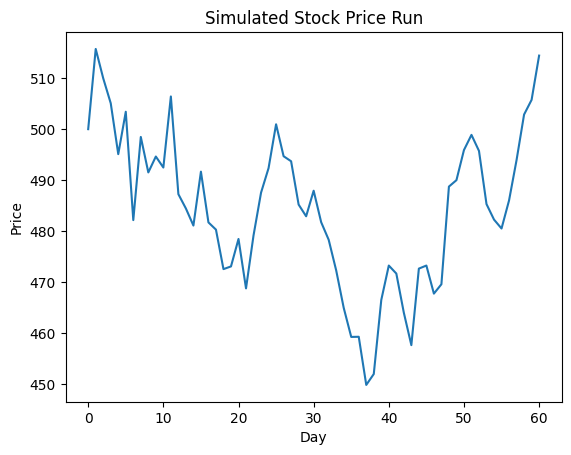

In [ ]:
np.random.seed(1)
part_a_run = simulate_stock(500, 0.08, 0.3, 60)

plt.plot(part_a_run)
plt.xlabel("Day")
plt.ylabel("Price")
plt.title("Simulated Stock Price Run")
plt.show()

## Part B: Annual Yield Function

In this section, we will create and test a function that takes a simulated run as its input, and calculates the annual yield for that particular run.

Write a function named `find_yield`. This function should accept a single parameter called `run`, which is expected to be an array of simulated daily prices for a stock. The function should return the annual yield for the stock over the simulated period, rounded to four decimal places.

The formula for calculating the annual yield is as follows:

$$\text{annual yield} = \ln\left(\frac{\text{Final Price}}{\text{Initial Price}}\right) \cdot \frac{252}{\text{Days in Run}}$$

You can use the function `math.log` in the `math` package to calculate the natural logarithm.

Recall that the number of days in a run is equal to one less than the length of the run, since the run contains the starting price.

In [ ]:
def find_yield(run):
  initial_price = run[0]
  final_price = run[-1]

  days = len(run) - 1
  annual_yield = math.log(final_price / initial_price) * (252 / days)
  return round(annual_yield, 4)

Call the `find_yield` function on the run you created in Part A, printing the result. If everything is correct, you should get 0.1196 as the result. Note that this is quite a bit different from the expected 8% annual yield that we used to simulate this run. This is a result of the randomness involved in our simulation.

In [ ]:
print(find_yield(part_a_run))

0.1196


To get a sense as to the amount of variation possible in our simulations, we will create 25 simulated runs, all with the same set of parameters. We will plot these runs and will calculate the annual yield for each run.

In the cell below, use a loop to create 25 simulated runs for a stock with a current price of 100, an expected annual yield of 6%, and an annual volatility of 0.4 over a period of 200 days. Plot all 25 runs in the same line plot. For each run, use `find_yield` to calculate the annual yield for the run, and store the value in a list. You should see a wide range of simulated results.

**Hint:** Each iteration of your loop should do three things: simulate a run, calculate the yield for that run and add the result to a list, and add a line plot of the run to a figure using `plt.plot`.

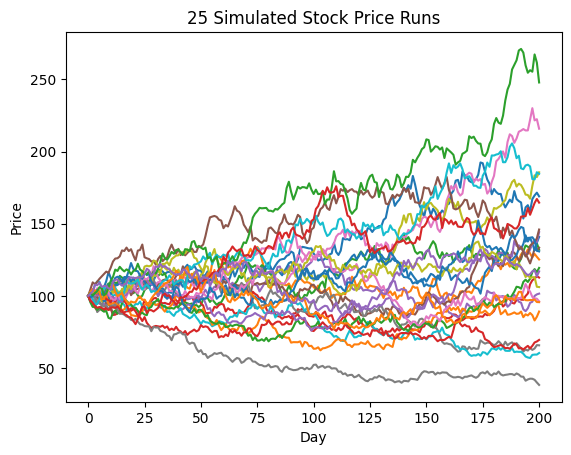

In [ ]:
part_b_run = []

for i in range(25):
 run = simulate_stock(100, 0.06, 0.4, 200)
 annual_yield = find_yield(run)
 part_b_run.append(annual_yield)

 plt.plot(run)

plt.xlabel("Day")
plt.ylabel("Price")
plt.title("25 Simulated Stock Price Runs")
plt.show()

Print the list of annual yields created in the previous code cell. Again, you will likely see a wide range of results.

In [ ]:
print(run)

[100.   101.6  103.14 107.79 107.36 109.21 106.23 106.94 106.88 105.32
 104.49 109.7  111.1  111.46 108.43 107.11 107.98 108.62 112.73 112.83
 112.46 112.44 112.74 112.59 113.1  115.   118.87 117.67 113.82 115.63
 120.32 120.1  122.22 120.03 120.68 119.37 118.45 116.66 115.5  114.46
 115.01 115.43 118.31 118.06 115.3  114.65 111.56 114.43 117.63 113.87
 110.22 113.58 112.38 112.64 106.76 110.19 115.34 116.3  113.51 118.35
 118.81 118.12 124.33 121.52 123.55 119.9  122.32 120.7  117.08 123.2
 123.54 120.67 116.15 113.99 117.38 117.14 113.93 118.5  115.5  115.32
 116.65 116.32 116.91 110.43 102.64 103.68 100.7  102.81 100.37  96.5
  96.15  95.14  95.07  98.79  96.9   96.26  98.79  97.74  95.29  95.76
  97.15  91.43  89.81  91.15  92.28  93.17  92.81  89.83  89.42  93.26
  95.35  90.65  88.42  86.17  88.12  89.74  93.86  96.88  94.1   94.27
  92.93  89.3   90.94  93.11  92.28  95.9   99.12  98.51  97.59 100.03
 102.79 101.41 101.28 103.61 108.55 110.18 114.76 116.44 114.21 117.4
 124.25 1

## Part C: Finding Seeds that Generate Specific Outcomes

The purpose of this section is to give you some experience working with seeds. Through trial-and-error, you will try to find seeds that result in specific outcomes.

In the cell below, Stock A has the highest simulated final price.

Use NumPy to set the random seed to an integer of your choice. Simulate daily runs for three stocks (Stock A, Stock B, and Stock C) over a period of 100 days. The parameters for these stocks are as follows:

* Stock A has a current price of 78, an expected annual return of 4%, and a volatility of 1.2.
* Stock B has a current price of 75, an expected annual return of 8%, and a volatility of 0.8.
* Stock C has a current price of 72, an expected annual return of 16%, and a volatility of 0.6.

Create line plots for all three runs on the same figure, including a legend indicating which line goes with which stock. Change the seed until you get a result in which Stock A has the highest final price after 100 days.

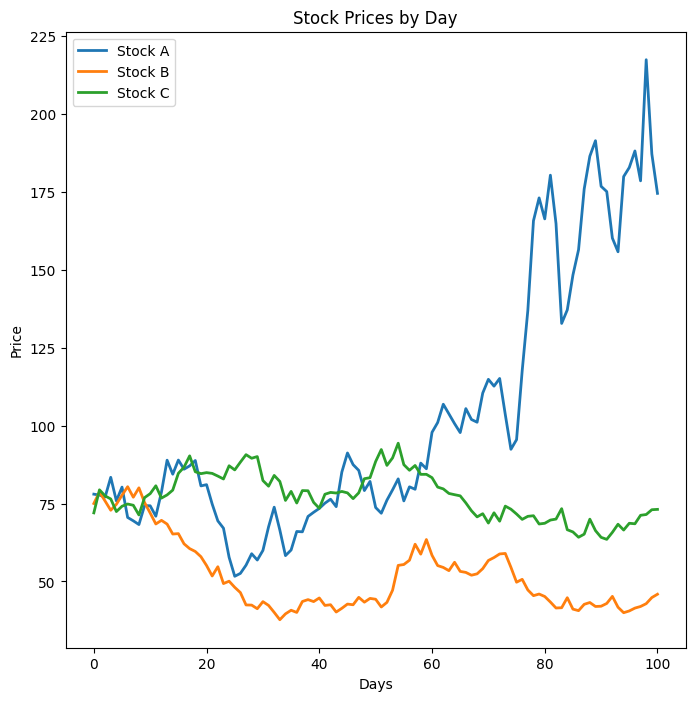

In [ ]:
np.random.seed(21)
days = 100

stock_A = simulate_stock(78, 0.04, 1.2, days)
stock_B = simulate_stock(75, 0.08, 0.8, days)
stock_C = simulate_stock(72, 0.16, 0.6, days)

x = range(days + 1)

plt.figure(figsize=[8,8])
plt.plot(x, stock_A, lw=2, label='Stock A') ## this should be highest
plt.plot(x, stock_B, lw=2, label='Stock B')
plt.plot(x, stock_C, lw=2, label='Stock C')
plt.legend()
plt.xlabel('Days')
plt.ylabel('Price')
plt.title('Stock Prices by Day')
plt.show()

In the cell below, Stock B has the highest simulated final price.

Repeat the steps in the previous code cell, but select a seed that results in Stock B having the highest final price after 100 days.

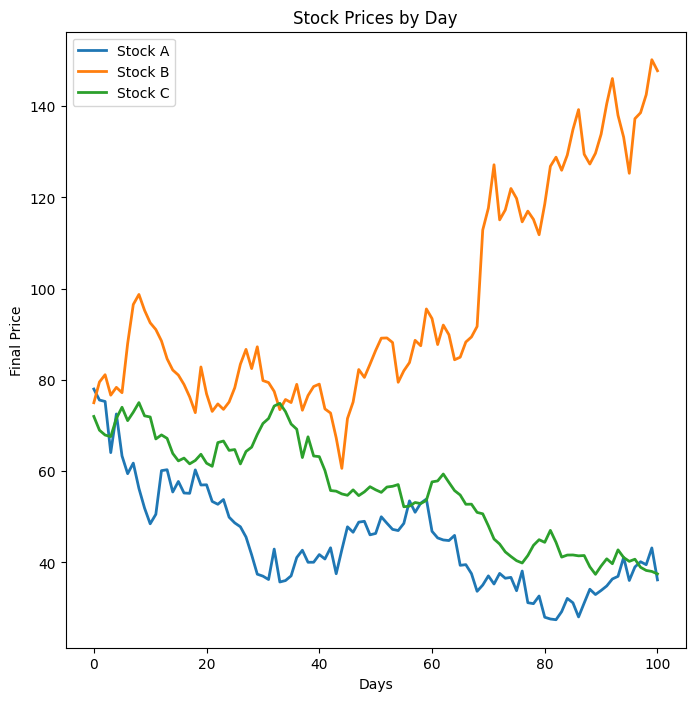

In [ ]:
np.random.seed(2)
days = 100

stock_A = simulate_stock(78, 0.04, 1.2, days)
stock_B = simulate_stock(75, 0.08, 0.8, days)
stock_C = simulate_stock(72, 0.16, 0.6, days)

x = range(days + 1)

plt.figure(figsize=[8,8])
plt.plot(x, stock_A, lw=2, label='Stock A')
plt.plot(x, stock_B, lw=2, label='Stock B') ## this should be highest
plt.plot(x, stock_C, lw=2, label='Stock C')
plt.legend()
plt.xlabel('Days')
plt.ylabel('Final Price')
plt.title('Stock Prices by Day')
plt.show()

In the cell below, Stock C has the highest simulated final price.

Repeat the steps in the previous code cell, but select a seed that results in Stock C having the highest final price after 100 days.

**Note:** Each student should use their own unique seed values for this part. When you have found three seed values that generate the desired results, please email them to your instructor (or follow whatever process your instructor provides for claiming seeds). Points may be deducted if you use seed values claimed by another student.

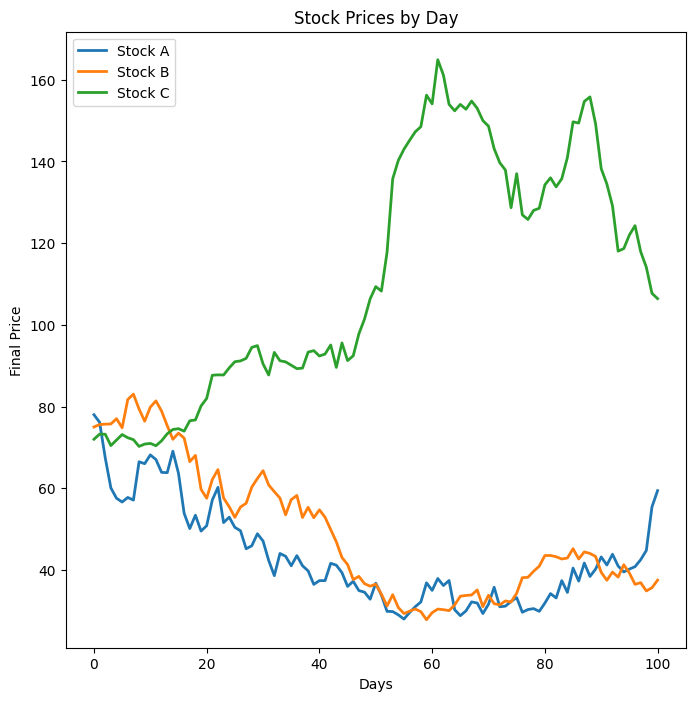

In [ ]:
np.random.seed(33)
days = 100

stock_A = simulate_stock(78, 0.04, 1.2, days)
stock_B = simulate_stock(75, 0.08, 0.8, days)
stock_C = simulate_stock(72, 0.16, 0.6, days)

x = range(days + 1)

plt.figure(figsize=[8,8])
plt.plot(x, stock_A, lw=2, label='Stock A')
plt.plot(x, stock_B, lw=2, label='Stock B')
plt.plot(x, stock_C, lw=2, label='Stock C') ## this should be highest
plt.legend()
plt.xlabel('Days')
plt.ylabel('Final Price')
plt.title('Stock Prices by Day')
plt.show()

## Part D: Monte Carlo Simulation

As we have seen, any two runs generated from the same set of parameters might vary considerably from one another. You might be asking how simulation is useful if we get very different results every time we run a simulation. The answer is that we do not expect simulation to be able to tell us exactly what will occur; we use it to get an idea of the range of possible outcomes that might occur. In order to perform that sort of analysis, we need to perform many simulations, and then look at the range of outcomes occurring in these simulations. The process of performing several simulations to estimate probabilities relating to the outcome of a certain event is called **Monte Carlo simulation**.

Write a function named `monte_carlo`. The function should accept five parameters: `start`, `rate`, `vol`, `days`, and `num_runs`. The function should use a loop to generate a number of simulated stock runs equal to `num_runs`. The characteristics of the runs are provided by the parameters `start`, `rate`, `vol`, and `days`.

Each time your loop executes, the following steps should be performed:

1. Simulate a run using the supplied parameters. Store the resulting array in a variable.
2. Determine the final simulated price of the stock and append it into a list called `final_prices`.
3. Determine the annual yield for the simulated run and append it into a list called `annual_yields`.

When the loop is done executing, convert the two lists you have constructed to NumPy arrays and return both of them.

In [ ]:
def monte_carlo(start, rate, vol, days, num_runs):
  final_prices = []
  annual_yields = []

  for i in range(num_runs):
    run = simulate_stock(start, rate, vol, days)

    final_prices.append(run[-1])
    annual_yields.append(find_yield(run))
  return np.array(final_prices), np.array(annual_yields)

We will now test the function by running a Monte Carlo simulation with a specific seed.

Set a seed of 1, and run a Monte Carlo simulation consisting of 10,000 simulated runs for a stock with a current price of 200, an expected annual return of 10%, and a volatility of 0.4. Each run should be over a period of 500 days. Create a histogram of the final prices. Use `bins=np.arange(0, 1600, 50)`, and set the `edgecolor` to black. Set the size of the figure to be `[10, 5]`.

If your code is correct, your histogram should have a peak around 200 and should have a long tail trailing off to the right. This shows that the majority of the simulated final prices are near 200, but there are some very large outliers.

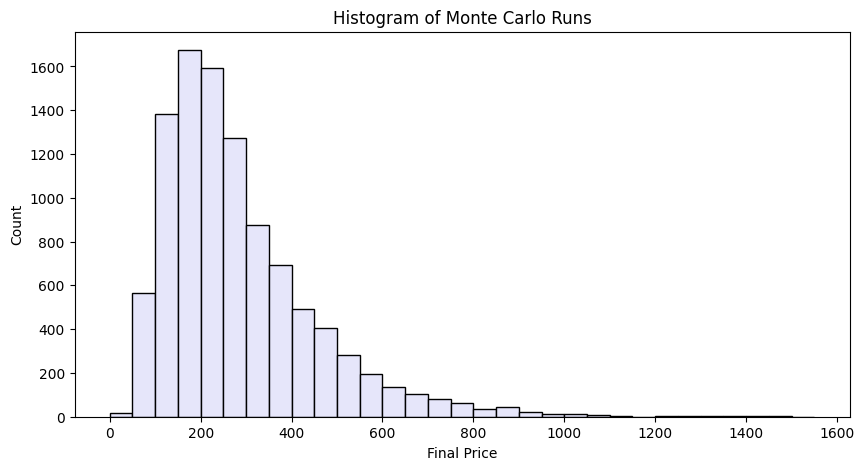

In [ ]:
np.random.seed(1)

final_prices, annual_yields = monte_carlo(200, 0.10, 0.4, 500, 10000)

plt.figure(figsize=[10, 5])
plt.hist(final_prices, edgecolor='k', color='lavender',
         bins=np.arange(0, 1600, 50))
plt.title('Histogram of Monte Carlo Runs')
plt.xlabel('Final Price')
plt.ylabel('Count')
plt.show()

Use `np.percentile` to calculate the 10th, 25th, 50th, 75th, and 90th percentiles for the final prices in the simulated runs generated for the stock. Display the results by creating five lines of output, with each line using the following format:

```
__th percentile: _____
```

Round the displayed percentiles to 2 decimal places.

If done correctly, you should get a 10th percentile of 118.05 and a 90th percentile of 505.91.

In [ ]:
percentiles = [10, 25, 50, 75, 90]

for p in percentiles:
  result = np.round(np.percentile(final_prices, p), 2)
  print(f"{p}th percentile: {result:.2f}")

10th percentile: 118.05
25th percentile: 165.57
50th percentile: 242.95
75th percentile: 357.56
90th percentile: 505.91


## Part E: Effects of Volatility

In this part, we will explore the effect of volatility on simulated stock prices. We will do this by performing two Monte Carlo simulations. The two simulations will use different volatilities, but will otherwise use the same parameters.

Set a seed of 1 and then run Monte Carlo simulations for two stocks (Stock A and Stock B), each with 10,000 runs lasting over a period of 150 days. Both stocks being simulated have a current price of 100, and an expected annual yield of 12%. However, Stock A has a volatility of 0.3, and Stock B has a volatility of 0.7.

Calculate the average of the simulated annual yields for each stock, rounded to four decimal places. Print the results in the following format:

```
Average Annual Yield for A over 10000 runs: _____
Average Annual Yield for B over 10000 runs: _____
```

In [ ]:
np.random.seed(1)

final_A, yields_A = monte_carlo(100, 0.12, 0.3, 150, 10000)
final_B, yields_B = monte_carlo(100, 0.12, 0.7, 150, 10000)

avg_A = np.round(np.mean(yields_A), 4)
avg_B = np.round(np.mean(yields_B), 4)

print(f"Average Annual Yield for A over 10000 runs: {avg_A:.4f}")
print(f"Average Annual Yield for B over 10000 runs: {avg_B:.4f}")

Average Annual Yield for A over 10000 runs: 0.1218
Average Annual Yield for B over 10000 runs: 0.1128


We will now visually inspect the results of the two Monte Carlo simulations by plotting histograms of the final prices.

Use `plt.hist` to create a figure with two histograms on the same axes. Each histogram should display the distribution of final prices for each stock over the 10,000 simulated runs. Set a figure size of `[10, 5]`. Set an alpha level of 0.6 and use `np.arange(0, 600, 10)` for the bins in each plot. Set the `edgecolor` to black. Display a legend indicating which histogram is for which stock. Finally, set the title of the figure to be `"Histogram of Final Prices over 10,000 Runs"`.

You should see that the histogram for Stock A is tightly clustered with a peak near 120. The histogram for Stock B should have a shorter peak near 80, and a large tail trailing off to the right. This shows that the stock with the higher volatility (Stock B) has a much wider range of likely outcomes.

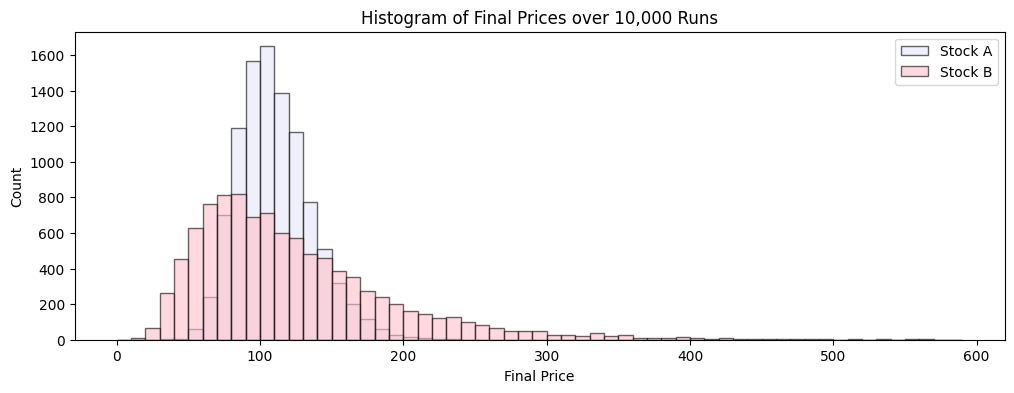

In [ ]:
plt.figure(figsize=[12, 4])

plt.hist(final_A, edgecolor='k', color='lavender', alpha=0.6, label='Stock A',
         bins = np.arange(0,600, 10))

plt.hist(final_B, edgecolor='k', color='pink', alpha=0.6, label='Stock B',
         bins=np.arange(0, 600, 10))

plt.title('Histogram of Final Prices over 10,000 Runs')
plt.xlabel('Final Price')
plt.ylabel('Count')
plt.legend()

plt.show()

## Part F: Comparing Two Stocks

In this section, we will use Monte Carlo simulation to estimate probabilities relating to the performance of two stocks with different parameters.

Set a seed of 1, and then run Monte Carlo simulations for two stocks (Stock A and Stock B), each with 10,000 runs lasting over a period of 252 days. Both stocks being simulated have a current price of 120. Stock A has an expected annual yield of 8% and a volatility of 0.2. Stock B has an expected annual yield of 5% and a volatility of 0.5.

Calculate the following:

* The proportion of the simulated runs in which Stock A has a higher final price than Stock B.
* The proportion of the simulated runs in which Stock A has a final price greater than 150.
* The proportion of the simulated runs in which Stock B has a final price greater than 150.
* The proportion of the simulated runs in which Stock A has a final price less than 100.
* The proportion of the simulated runs in which Stock B has a final price less than 100.

Round all values to four decimal places, and display your results in the following format:

```
Proportions of runs in which...
-------------------------------
A ends above B:   xxxx

A ends above 150: xxxx
B ends above 150: xxxx

A ends below 100: xxxx
B ends below 100: xxxx
```

In [ ]:
np.random.seed(1)

final_A, yields_A = monte_carlo(120, 0.08, 0.2, 252, 10000)
final_B, yields_B = monte_carlo(120, 0.05, 0.5, 252, 10000)

prop_A_above_B = np.round(np.mean(final_A > final_B), 4)
prop_A_above_150 = np.round(np.mean(final_A > 150), 4)
prop_B_above_150 = np.round(np.mean(final_B > 150), 4)
prop_A_below_100 = np.round(np.mean(final_A < 100), 4)
prop_B_below_100 = np.round(np.mean(final_B < 100), 4)


print(f"Proportions of runs in which...")
print(f"-------------------------------")
print(f"A ends above B: {prop_A_above_B:.4f}")
print(f"\nA ends above 150: {prop_A_above_150:.4f}")
print(f"B ends above 150: {prop_B_above_150:.4f}")
print(f"\nA ends below 100: {prop_A_below_100:.4f}")
print(f"B ends below 100: {prop_B_below_100:.4f}")

Proportions of runs in which...
-------------------------------
A ends above B: 0.5206

A ends above 150: 0.2338
B ends above 150: 0.3619

A ends below 100: 0.0950
B ends below 100: 0.3195


## Part G: Expected Call Payoff

We will conclude this project by exploring an application of Monte Carlo simulation. A **call option** is a particular type of investment whose final value (or payoff) is based on the price of a stock. When you purchase a call based on a stock, it will have a specified expiration date, as well as a strike price that we will denote by $K$. Let $S$ denote the price of the stock when the call expires. If $S > K$, then you will receive a payoff of $S - K$ dollars from your call. If $S \leq K$, then your payoff would be \$0.

For example, assume that you pay $10 for a call on a stock. Suppose that the call expires in one year and has a strike price of $120. If the price of the stock one year later is \$150, then you will receive a payoff of \$30 from the call. If, on the other hand, the price of the stock after one year was \$110, then you would not get any money back from the call (your payoff would be \$0).

In a sense, you can think of a call option as a "bet" that the price of the stock will be greater than the strike price when the call expires.

We will use Monte Carlo simulation to estimate the expected payoff of a call on a particular stock. The stock will have a current price of 200, an expected annual yield of 11%, and a volatility of 0.4. The call will have a strike price of 225 and will expire in 150 days.

Run a Monte Carlo simulation for a stock with a current price of 200, an expected annual yield of 11%, and a volatility of 0.4. Use 10,000 runs in the simulation. Each run should last 150 days.

Consider a call with a strike price of 225. Calculate the payoff of this call for each of the 10,000 simulated runs of the stock. You can do this by first subtracting 225 from each of the final stock prices, and then setting any negative values to zero. To set the negative values to zero, you can use Boolean masking or `np.where`.

Print the average call payoff over the 10,000 runs. Set a seed of 1 at the beginning of this cell.

**Note:** This section should not contain any loops.

In [ ]:
np.random.seed(1)

final_prices, annual_yields = monte_carlo(200, 0.11, 0.4, 150, 10000)

payoffs = np.where(final_prices - 225 > 0,
                   final_prices - 255,
                   0)
avg_payoff = np.round(np.mean(payoffs), 4)
print(avg_payoff)

14.0897


# Submission Instructions

1. Perform a Restart and Run All by clicking **Runtime > Restart session and run all**.
2. Copy the link to your notebook by clicking **Share > Copy Link**.
3. Paste the copied link into the notebook renderer tool to generate an HTML export of your notebook.
4. Save the resulting HTML file to your local machine.
5. Submit the HTML file to Canvas.